In [1]:
import numpy as np

import sys
import os

sys.path.append(os.path.abspath(os.path.join('..')))

from src.load_data_gait import *
from src.plot_data_gait import *
from src.train_LSTMGait import train_model

In [2]:
base_path = '../datasets/GAIT_signals/dataset/data'

In [3]:
lr = 0.001
dropout = 0.5
cnn_channels = [64, 128, 128]
kernel_size = 7
batch_size = 128
hidden_size = 256
window_size = 200
stride = 50

In [4]:
X, y, subjects = load_dataset_gait(base_path, process="free_raw", sensors=['LB'], window_size=window_size, stride=stride)
X = X.astype(np.float32)
y = y.astype(np.int64)


ckpt_path = "../checkpoints/loco"

Trials descartados: 10 ['HS_2_1', 'KOA_17_3', 'KOA_17_4', 'PD_6_4', 'PD_6_5', 'RIL_24_6', 'RIL_24_7', 'RIL_24_9', 'RIL_31_12', 'RIL_42_2'] | sujetos con datos: 260


In [5]:
from sklearn.model_selection import train_test_split

def loco_splits(subjects, seed=42):
    subjects = np.unique(subjects)
    cohort = np.array([s.split("_")[0] for s in subjects])
    for c in np.unique(cohort):
        test, rest = subjects[cohort == c], subjects[cohort != c]
        tr, va = train_test_split(rest, test_size=0.2, stratify=[s.split("_")[0] for s in rest], random_state=seed)
        yield c, dict(train=sorted(tr), val=sorted(va), test=sorted(test))

In [7]:
loco_test_results = {}
seed = 44
for c, split in loco_splits(subjects, seed=seed):
    print(f"Test split: {c}")
    trained_model, best_val_f1, test_f1, df_val_f1, df_test_f1 = train_model(
        X, y, subjects, model_name="cnnbilstm", norm="window", 
        epochs=200, lr=lr, patience=20, dropout=dropout, 
        cnn_channels=cnn_channels, kernel_size=kernel_size, 
        batch_size=batch_size, hidden_size=hidden_size, split=split, seed=seed, out_dir=f"{ckpt_path}_{c}_{seed}", plot=True)

    loco_test_results[c] = {
        "best_val_f1": best_val_f1,
        "test_f1": test_f1,
        "df_val_f1": df_val_f1,
        "df_test_f1": df_test_f1
    }

Test split: ACL
               →  train: 199 subjects (60895 windows)  |  val: 50 subjects (12306 windows)


Early stopping in epoch 86. Best F1: 0.9254

Val F1: 0.9254  |  Test F1: 0.9448
Checkpoint saved → ../checkpoints/loco_ACL_44/model.pt
Test split: CIPN
               →  train: 192 subjects (58281 windows)  |  val: 49 subjects (11995 windows)


Early stopping in epoch 74. Best F1: 0.9336

Val F1: 0.9336  |  Test F1: 0.9411
Checkpoint saved → ../checkpoints/loco_CIPN_44/model.pt
Test split: CVA
               →  train: 168 subjects (52703 windows)  |  val: 43 subjects (13882 windows)


Early stopping in epoch 50. Best F1: 0.9319

Val F1: 0.9319  |  Test F1: 0.8558
Checkpoint saved → ../checkpoints/loco_CVA_44/model.pt
Test split: HOA
               →  train: 196 subjects (59720 windows)  |  val: 49 subjects (11870 windows)


Early stopping in epoch 69. Best F1: 0.9390

Val F1: 0.9390  |  Test F1: 0.9044
Checkpoint saved → ../checkpoints/loco_HOA_44/model.pt
Test split: HS
               →  train: 149 subjects (50079 windows)  |  val: 38 subjects (10993 windows)


Early stopping in epoch 50. Best F1: 0.9092

Val F1: 0.9092  |  Test F1: 0.9470
Checkpoint saved → ../checkpoints/loco_HS_44/model.pt
Test split: KOA
               →  train: 193 subjects (58835 windows)  |  val: 49 subjects (12791 windows)


Early stopping in epoch 102. Best F1: 0.9250

Val F1: 0.9250  |  Test F1: 0.9425
Checkpoint saved → ../checkpoints/loco_KOA_44/model.pt
Test split: PD
               →  train: 188 subjects (56172 windows)  |  val: 48 subjects (10871 windows)


Early stopping in epoch 64. Best F1: 0.9280

Val F1: 0.9280  |  Test F1: 0.9305
Checkpoint saved → ../checkpoints/loco_PD_44/model.pt
Test split: RIL
               →  train: 167 subjects (40022 windows)  |  val: 42 subjects (9465 windows)


Early stopping in epoch 84. Best F1: 0.9235

Val F1: 0.9235  |  Test F1: 0.8448
Checkpoint saved → ../checkpoints/loco_RIL_44/model.pt


In [14]:
import json

ckpt_path = "../checkpoints"
pathologies = "ACL CIPN CVA HOA HS KOA PD RIL".split()
seeds_names = ["", "43", "44"]

val = {p: [] for p in pathologies}
test = {p: [] for p in pathologies}

for p in pathologies:
    for s in seeds_names:
        if s == "":
            s = "42"
            path = f"{ckpt_path}/loco_{p}/summary.json"
        else:
            path = f"{ckpt_path}/loco_{p}_{s}/summary.json"

        with open(path) as f:
            data = json.load(f)

        val[p].append(data["val_f1"])
        test[p].append(data["test_f1"])


val_mean = [np.mean(val[p]) for p in pathologies]
val_std = [np.std(val[p]) for p in pathologies]
test_mean = [np.mean(test[p]) for p in pathologies]
test_std = [np.std(test[p]) for p in pathologies]



In [21]:
def plot_loco_results(val_mean, val_std, test_mean, test_std, title="F1 by cohort. LOCO results.", ax=None):
    COLOR_MAP = {
        'HS':   ('Healthy',        'lightgreen',    'mediumseagreen'),
        'ACL':  ('Orthopaedic',    'lightcoral',    'indianred'),
        'HOA':  ('Orthopaedic',    'lightcoral',    'indianred'),
        'KOA':  ('Orthopaedic',    'lightcoral',    'indianred'),
        'CIPN': ('Neurological',   'lightblue',     'steelblue'),
        'CVA':  ('Neurological',   'lightblue',     'steelblue'),
        'PD':   ('Neurological',   'lightblue',     'steelblue'),
        'RIL':  ('Neurological',   'lightblue',     'steelblue'),
    }

    pathologies = "ACL CIPN CVA HOA HS KOA PD RIL".split()

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    x = np.arange(len(pathologies))
    width = 0.38

    seen_cohorts = set()
    for i, disease in enumerate(pathologies):
        cohort, color_val, color_test = COLOR_MAP.get(disease, ('Other', 'gray', 'dimgray'))
        show_legend = cohort not in seen_cohorts
        seen_cohorts.add(cohort)

        bar_val = ax.bar(x[i] - width/2, val_mean[i], width, yerr=val_std[i],
                         capsize=5, color=color_val, alpha=0.8,
                         label=f"{cohort} (Val)" if show_legend else "_nolegend_")
        bar_test = ax.bar(x[i] + width/2, test_mean[i], width, yerr=test_std[i],
                          capsize=5, color=color_test, alpha=0.8,
                          label=f"{cohort} (Test)" if show_legend else "_nolegend_")

        ax.bar_label(bar_val, fmt='%.3f', fontsize=8)
        ax.bar_label(bar_test, fmt='%.3f', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(pathologies)
    ax.set_ylim(0.6, 1.1)
    ax.set_ylabel('Mean Macro F1')
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.4)

    plt.tight_layout()

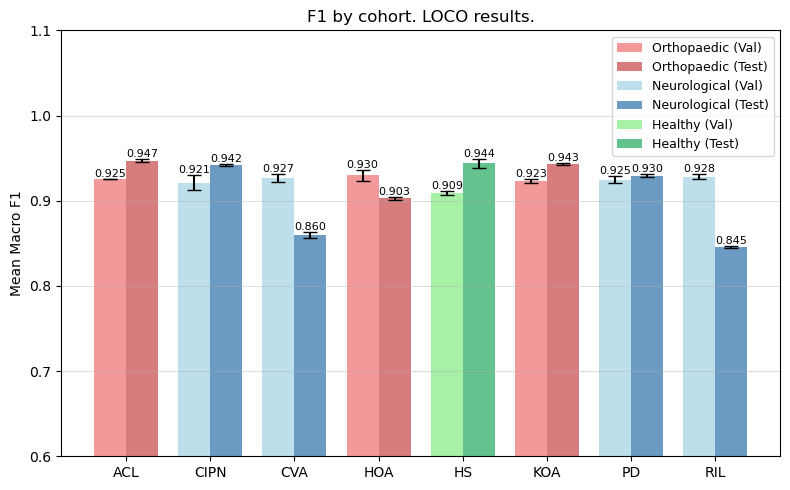

In [22]:
plot_loco_results(val_mean, val_std, test_mean, test_std)